In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Loading The Dataset
path = "train.csv"
df = pd.read_csv(path)

### Checking Data Quality

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [4]:
df.head(10)

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10
5,2013-01-06,1,1,12
6,2013-01-07,1,1,10
7,2013-01-08,1,1,9
8,2013-01-09,1,1,12
9,2013-01-10,1,1,9


In [5]:
# Convert the date column to datetime and setting it as Index
# This allows pandas to treat the data as real time series
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

In [6]:
# Adding up daily sales across all stores and items into monthly sales
monthly = df['sales'].resample('MS').sum().to_frame()
monthly.columns = ['Sales']
monthly = monthly.asfreq('MS')
df = monthly.copy()  # Replacing df with monthly series so the rest of the notebook uses it 

In [7]:
df.head()

,Sales
date,
2013-01-01,454904
2013-02-01,459417
2013-03-01,617382
2013-04-01,682274
2013-05-01,763242


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 60 entries, 2013-01-01 to 2017-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Sales   60 non-null     int64
dtypes: int64(1)
memory usage: 960.0 bytes


In [9]:
df.describe()

,Sales
count,6.000000e+01
mean,7.950752e+05
std,1.729018e+05
min,4.549040e+05
25%,6.617050e+05
50%,7.990180e+05
75%,9.220262e+05
max,1.171393e+06


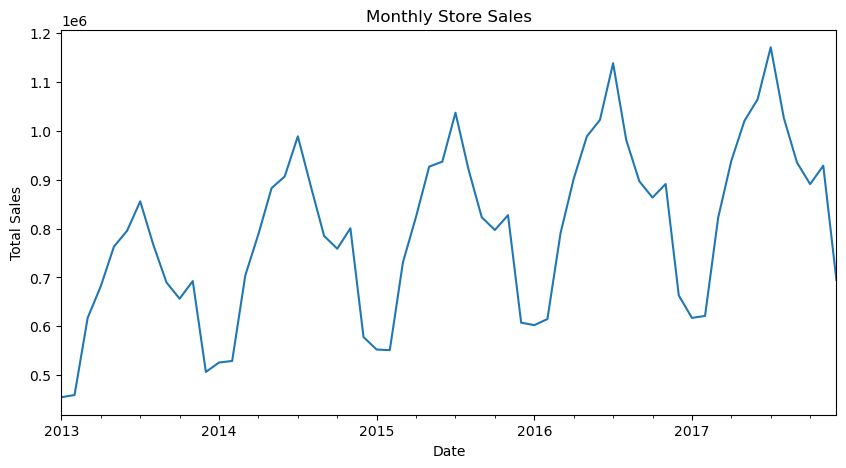

In [10]:
# Plotting the monthly series to look for trend and seasonality
df['Sales'].plot(title="Monthly Store Sales", figsize=(10,5))
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()

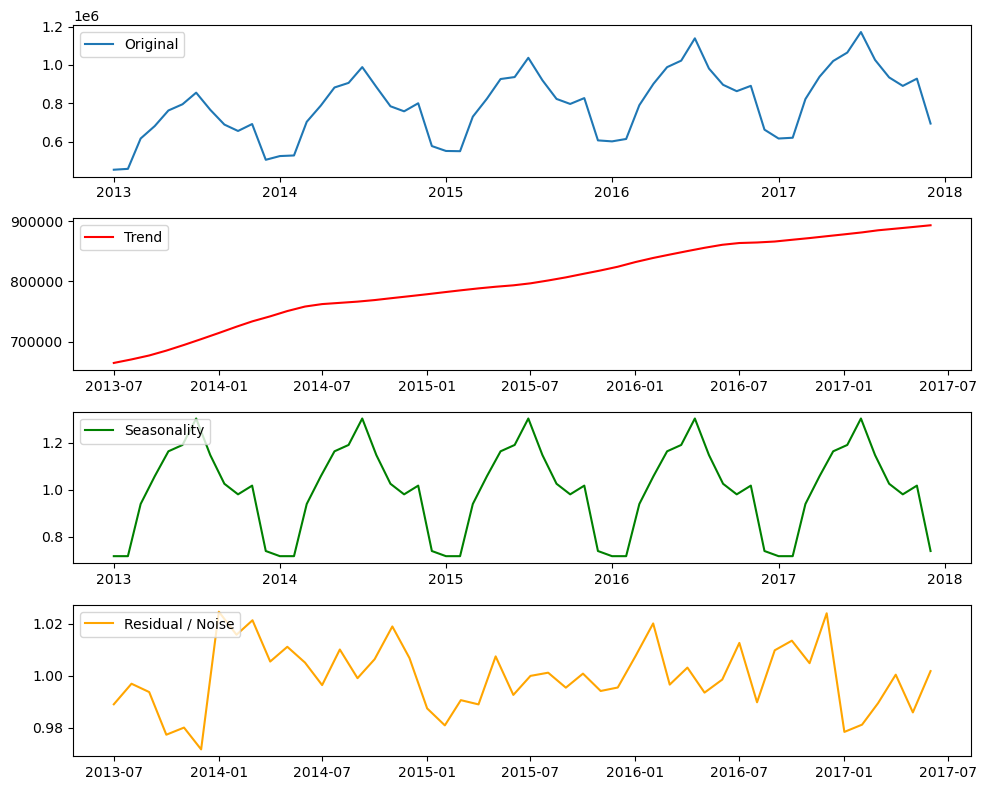

In [11]:
# Multiplicative Decomposition; splitting the series into seasonality and residual
# period=12 because the seasonal pattern repeats every 12 months
decomposition = seasonal_decompose(df['Sales'], model='multiplicative', period=12)

trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

plt.figure(figsize=(10,8))

plt.subplot(4,1,1)
plt.plot(df['Sales'], label='Original')
plt.legend(loc='upper left')

plt.subplot(4,1,2)
plt.plot(trend, label='Trend', color='red')
plt.legend(loc='upper left')

plt.subplot(4,1,3)
plt.plot(seasonal, label='Seasonality', color='green')
plt.legend(loc='upper left')

plt.subplot(4,1,4)
plt.plot(residual, label='Residual / Noise', color='orange')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

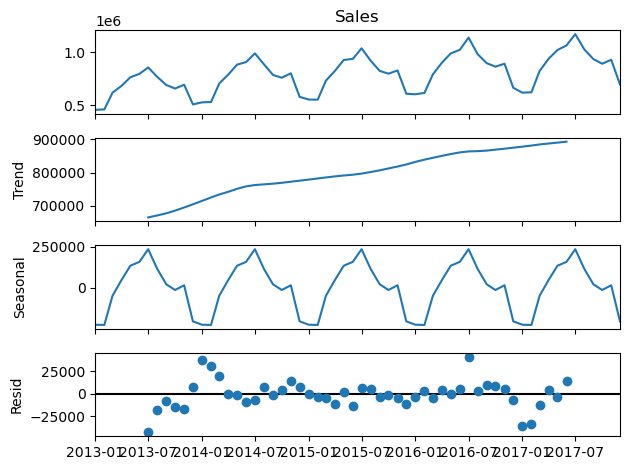

In [12]:
# plotting additive decomposition for comparison 
decomp_add = seasonal_decompose(df['Sales'], model='additive', period=12)
decomp_add.plot()
plt.show()

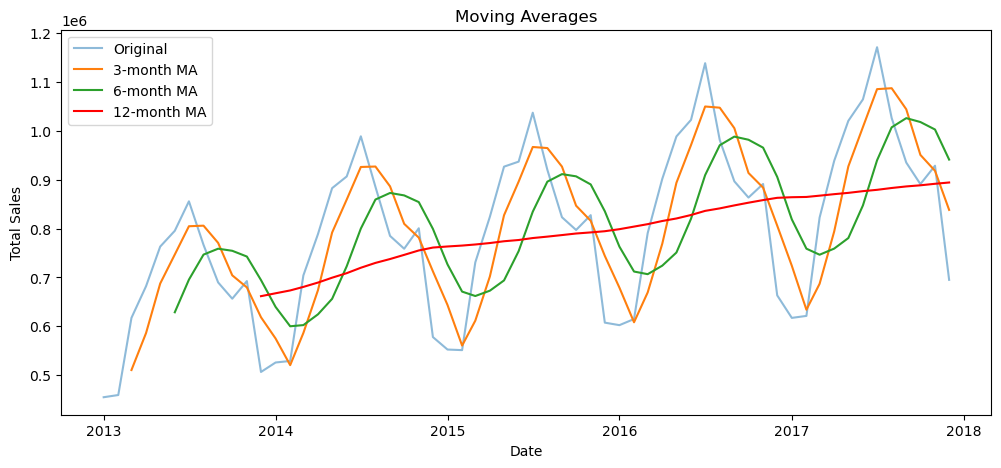

In [13]:
# Moving Average; this smooths out short term noise, a small window follows the data closely
# while a large window shows long-term trend
df['MA_3'] = df['Sales'].rolling(window=3).mean()
df['MA_6'] = df['Sales'].rolling(window=6).mean()
df['MA_12'] = df['Sales'].rolling(window=12).mean()

plt.figure(figsize=(12,5))
plt.plot(df['Sales'], label='Original', alpha=0.5)
plt.plot(df['MA_3'], label='3-month MA')
plt.plot(df['MA_6'], label='6-month MA')
plt.plot(df['MA_12'], label='12-month MA', color='red')
plt.title("Moving Averages")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.show()

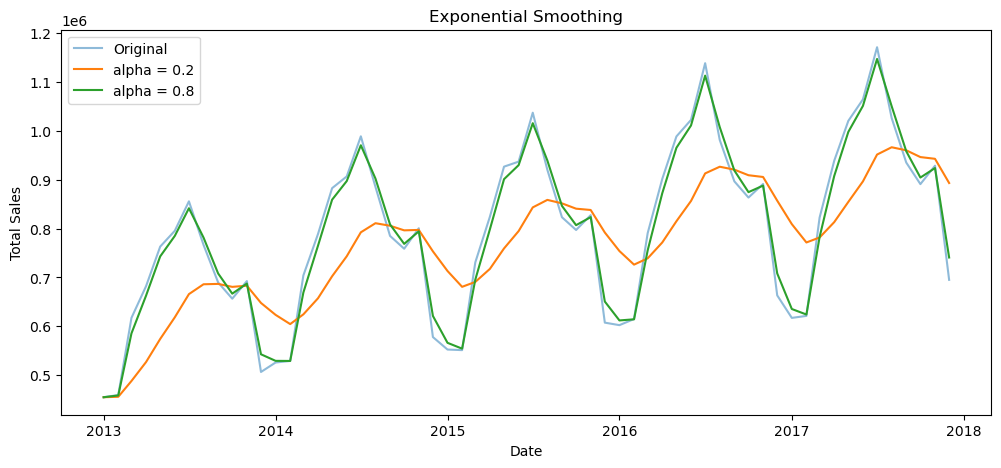

In [14]:
# Exponential smoothing; this guives recent months more weight than old ones
# alpha controls the speed; higher alpha = reacts faster to new data
df['EWM_0.2'] = df['Sales'].ewm(alpha=0.2, adjust=False).mean()
df['EWM_0.8'] = df['Sales'].ewm(alpha=0.8, adjust=False).mean()

plt.figure(figsize=(12,5))
plt.plot(df['Sales'], label='Original', alpha=0.5)
plt.plot(df['EWM_0.2'], label='alpha = 0.2')
plt.plot(df['EWM_0.8'], label='alpha = 0.8')
plt.title("Exponential Smoothing")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.show()

In [15]:
# Stationarity Test(ADF), if P.value < 0.05 suggests stationary
# The raw series looks like it has trend and seasonality, so we test it formally
from statsmodels.tsa.stattools import adfuller

def adf_check(series, name="Series"):
    result = adfuller(series.dropna())
    print(f"--- {name} ---")
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    if result[1] < 0.05:
        print("The series is likely stationary")
    else:
        print("The series is likely non-stationary")

In [16]:
adf_check(df['Sales'], "Original Series")

--- Original Series ---
ADF Statistic: -5.247518850016359
p-value: 7.026495391574466e-06
The series is likely stationary


In [17]:
# ADF result looked suspicious given visible trend, so we check the lags ADF used
# 11 lags on only 60 points can hide the seasonality
result = adfuller(df['Sales'])
print("Lags used by ADF:", result[2])
print("Critical values:", result[4])

Lags used by ADF: 11
Critical values: {'1%': np.float64(-3.5745892596209488), '5%': np.float64(-2.9239543084490744), '10%': np.float64(-2.6000391840277777)}


In [18]:
# KPSS Test(Has opposite nul hypothesis)
# Running this test as second option because the ADF looked unreliable 
from statsmodels.tsa.stattools import kpss

def kpss_check(series, name="Series"):
    stat, p, lags, crit = kpss(series.dropna(), regression='c', nlags="auto")
    print(f"--- KPSS: {name} ---")
    print('KPSS Statistic:', stat)
    print('p-value:', p)
    if p < 0.05:
        print("The series is likely non-stationary")
    else:
        print("The series is likely stationary")

kpss_check(df['Sales'], "Original Series")

--- KPSS: Original Series ---
KPSS Statistic: 0.5360443726944206
p-value: 0.03354856470846382
The series is likely non-stationary


### Differencing
KPSS disagreed with ADF and I trust the plot and KPSS so the series needs differencing

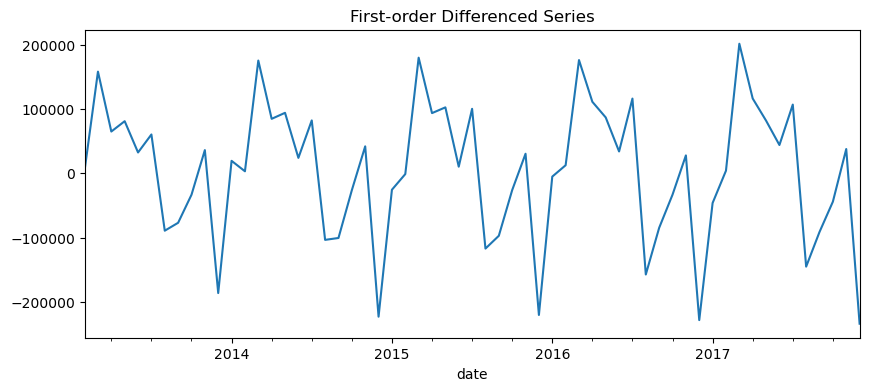

--- First Difference ---
ADF Statistic: -1.5289959815021819
p-value: 0.5191218072432541
The series is likely non-stationary


In [19]:
# First difference removes the trend by using month-to-month change
df['Diff_1'] = df['Sales'].diff(1)
df['Diff_1'].dropna().plot(title="First-order Differenced Series", figsize=(10,4))
plt.show()
adf_check(df['Diff_1'], "First Difference")

The result is still non-stationary because yearly waves remains 

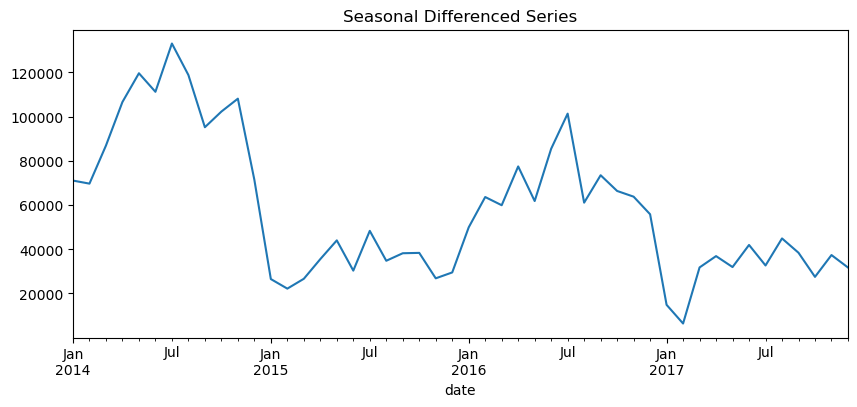

--- Seasonal Difference ---
ADF Statistic: -2.8981431620434477
p-value: 0.04556434893102982
The series is likely stationary


In [20]:
# Seasonal difference (lag 12) targets the yearly pattern left behind
df['Seasonal_Diff'] = df['Sales'].diff(12)
df['Seasonal_Diff'].dropna().plot(title="Seasonal Differenced Series", figsize=(10,4))
plt.show()
adf_check(df['Seasonal_Diff'], "Seasonal Difference")

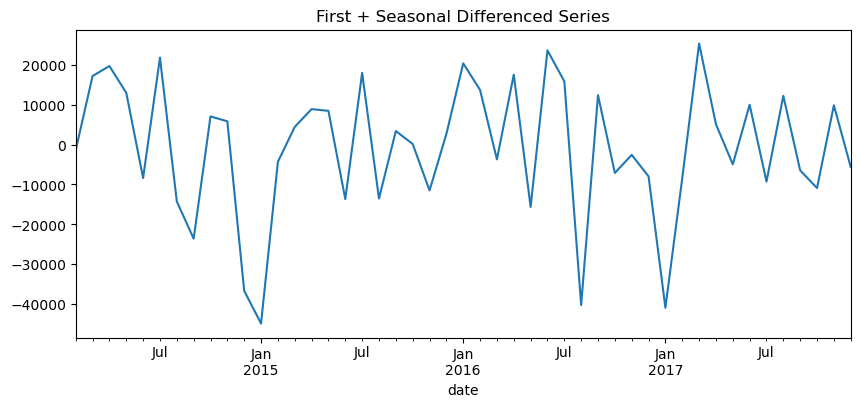

--- First + Seasonal Difference ---
ADF Statistic: -6.58535667590929
p-value: 7.3380645281641615e-09
The series is likely stationary


In [21]:
# Combining both differences removes the trend and the seasonality together
df['Both_Diff'] = df['Sales'].diff(1).diff(12)
df['Both_Diff'].dropna().plot(title="First + Seasonal Differenced Series", figsize=(10,4))
plt.show()
adf_check(df['Both_Diff'], "First + Seasonal Difference")

 Result: p ≈ 7e-9, clearly stationary, so we use d = 1 and D = 1

In [22]:
# KPSS confirms the combined difference, since ADF alone was misleading us earlier
kpss_check(df['Both_Diff'], "First + Seasonal Difference")

--- KPSS: First + Seasonal Difference ---
KPSS Statistic: 0.060451169570030355
p-value: 0.1
The series is likely stationary


### ACF and PACF
d and D are settled, so ACF/PACF help pick the p, q, P, Q orders

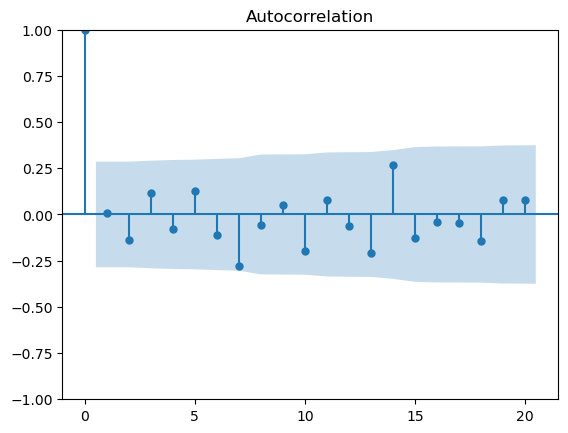

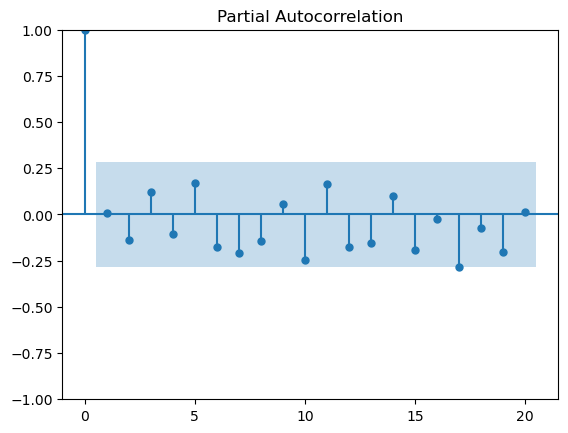

In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(df['Both_Diff'].dropna(), lags=20)
plt.show()

plot_pacf(df['Both_Diff'].dropna(), lags=20)
plt.show()

### Time Based train/split

In [24]:
# Splitting by time (80/20), not randomly, so the model can't see future months
# 60 months gives 48 train and 12 test, one full seasonal cycle
train_size = int(len(df) * 0.8)

train = df['Sales'][:train_size]
test = df['Sales'][train_size:]

In [25]:
print(len(train), len(test))
train.tail()

48 12


date
2016-08-01    981494
2016-09-01    896831
2016-10-01    863637
2016-11-01    891448
2016-12-01    663411
Freq: MS, Name: Sales, dtype: int64

In [26]:
test.head()

date
2017-01-01     617306
2017-02-01     621369
2017-03-01     822667
2017-04-01     938862
2017-05-01    1020686
Freq: MS, Name: Sales, dtype: int64

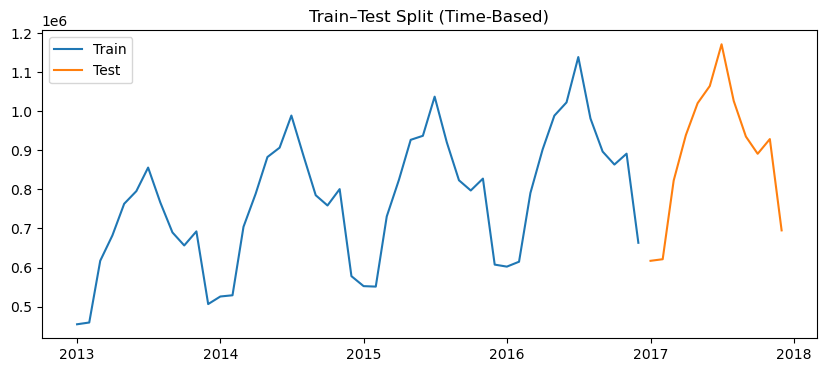

In [27]:
plt.figure(figsize=(10,4))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.legend()
plt.title("Train–Test Split (Time-Based)")
plt.show()

### Evaluation Helper
 One function to score every model on the same metrics (RMSE, MAE, MAPE)

In [28]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate(actual, predicted, name="Model"):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f"{name} -> RMSE: {rmse:.2f} | MAE: {mae:.2f} | MAPE: {mape:.2f}%")
    return rmse

### Plain ARIMA

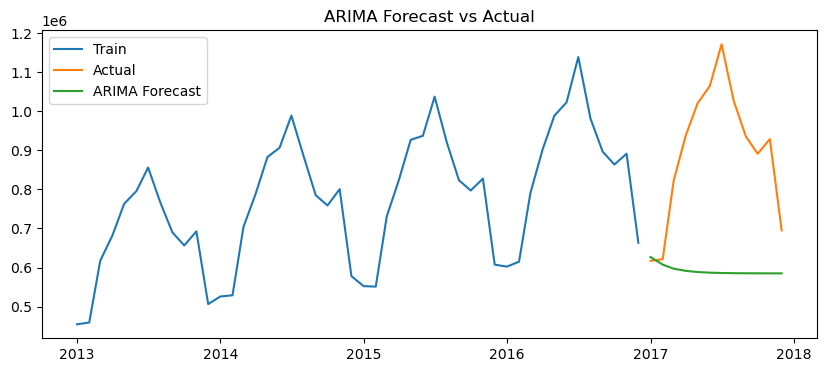

ARIMA(1,1,1) -> RMSE: 349954.06 | MAE: 303462.77 | MAPE: 31.07%


In [29]:
# Plain ARIMA uses d = 1 from the differencing step but has no seasonal terms
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))

plt.figure(figsize=(10,4))
plt.plot(train, label='Train')
plt.plot(test, label='Actual')
plt.plot(arima_forecast, label='ARIMA Forecast')
plt.legend()
plt.title("ARIMA Forecast vs Actual")
plt.show()

rmse_arima = evaluate(test, arima_forecast, "ARIMA(1,1,1)")

### SARIMA
ARIMA failed on seasonality, so SARIMA adds seasonal terms with D = 1 and s = 12

In [30]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(train,
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 12))
sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   48
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -383.689
Date:                            Sun, 22 Nov 2026   AIC                            777.379
Time:                                    11:22:39   BIC                            785.156
Sample:                                01-01-2013   HQIC                           780.063
                                     - 12-01-2016                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0043     42.002     -0.000      1.000     -82.326      82.318
ma.L1         -0.0015     41.923  -

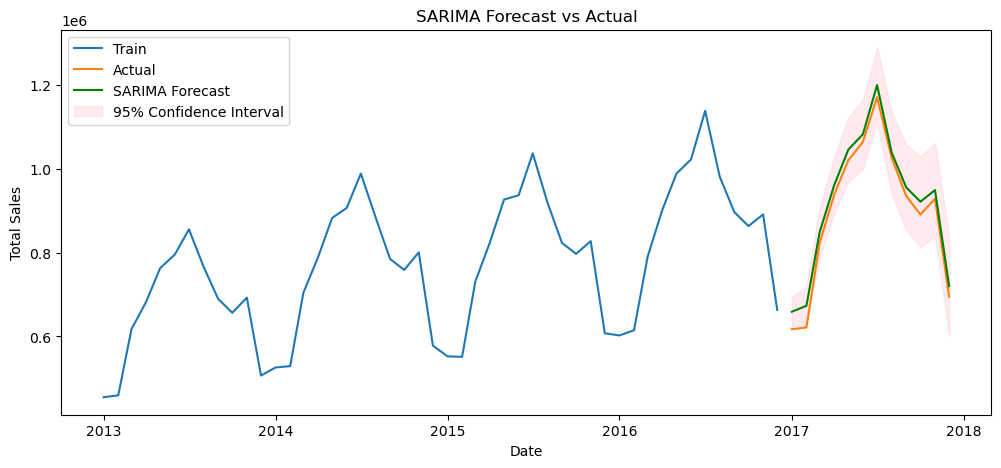

SARIMA(1,1,1)(1,1,1,12) -> RMSE: 28890.28 | MAE: 27043.67 | MAPE: 3.34%


In [31]:
# Forcasting the 12 test months with a 95% confidence band

sarima_pred = sarima_fit.get_forecast(steps=len(test))
sarima_forecast = sarima_pred.predicted_mean
conf_int = sarima_pred.conf_int()

plt.figure(figsize=(12,5))
plt.plot(train, label='Train')
plt.plot(test, label='Actual')
plt.plot(sarima_forecast, label='SARIMA Forecast', color='green')
plt.fill_between(conf_int.index,
                 conf_int.iloc[:, 0],
                 conf_int.iloc[:, 1],
                 color='pink', alpha=0.3, label='95% Confidence Interval')
plt.legend()
plt.title("SARIMA Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()

rmse_sarima = evaluate(test, sarima_forecast, "SARIMA(1,1,1)(1,1,1,12)")

### Order search by AIC
(1,1,1)(1,1,1,12) was only a starting guess, so we test other small orders
AIC picks the best fit with a complexity penalty; kept small (0 or 1) because of 48 training points

In [32]:
import itertools

p = q = P = Q = [0, 1]
results = []

for order in itertools.product(p, [1], q):
    for seasonal in itertools.product(P, [1], Q):
        try:
            m = SARIMAX(train, order=order,
                        seasonal_order=seasonal + (12,)).fit(disp=False)
            results.append((order, seasonal + (12,), m.aic))
        except:
            continue

results_df = pd.DataFrame(results, columns=['order', 'seasonal_order', 'AIC'])
results_df.sort_values('AIC')

,order,seasonal_order,AIC
2,"(0, 1, 0)","(1, 1, 0, 12)",767.799388
1,"(0, 1, 0)","(0, 1, 1, 12)",770.819739
3,"(0, 1, 0)","(1, 1, 1, 12)",772.724096
9,"(1, 1, 0)","(0, 1, 1, 12)",773.681866
5,"(0, 1, 1)","(0, 1, 1, 12)",773.779386
10,"(1, 1, 0)","(1, 1, 0, 12)",774.061312
6,"(0, 1, 1)","(1, 1, 0, 12)",774.156476
13,"(1, 1, 1)","(0, 1, 1, 12)",775.474009
11,"(1, 1, 0)","(1, 1, 1, 12)",775.588147
7,"(0, 1, 1)","(1, 1, 1, 12)",775.686189


In [33]:
# AIC only measures training fit, so we test the winner on the unseen 12 months
best = results_df.sort_values('AIC').iloc[0]
print(best)

best_model = SARIMAX(train,
                     order=best['order'],
                     seasonal_order=best['seasonal_order']).fit(disp=False)

best_forecast = best_model.forecast(steps=len(test))
rmse_best = evaluate(test, best_forecast, "Best SARIMA (AIC)")

order                 (0, 1, 0)
seasonal_order    (1, 1, 0, 12)
AIC                  767.799388
Name: 2, dtype: object
Best SARIMA (AIC) -> RMSE: 31023.79 | MAE: 29357.11 | MAPE: 3.60%


### Seasonal naive benchmark
 A 3.34% MAPE only means something against a baseline, so we predict each month

In [34]:
naive_forecast = df['Sales'].shift(12)[train_size:]
rmse_naive = evaluate(test, naive_forecast, "Seasonal Naive")

Seasonal Naive -> RMSE: 33093.80 | MAE: 31381.67 | MAPE: 3.44%


### Holt-Winters (Exponential smoothing as a forcaster)
Exponential smoothing as a real forecaster, with trend and seasonality
 Both seasonal types are tried because the yearly swings may grow with the sales level

In [35]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_add = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit()
hw_mul = ExponentialSmoothing(train, trend='add', seasonal='mul', seasonal_periods=12).fit()

hw_add_forecast = hw_add.forecast(len(test))
hw_mul_forecast = hw_mul.forecast(len(test))

rmse_hw_add = evaluate(test, hw_add_forecast, "Holt-Winters (additive)")
rmse_hw_mul = evaluate(test, hw_mul_forecast, "Holt-Winters (multiplicative)")

Holt-Winters (additive) -> RMSE: 26607.98 | MAE: 21301.66 | MAPE: 2.77%
Holt-Winters (multiplicative) -> RMSE: 43027.49 | MAE: 41610.81 | MAPE: 4.69%


### Model Comparison

In [36]:
# All six models ranked by RMSE
comparison = pd.DataFrame({
    'Model': ['ARIMA(1,1,1)', 'SARIMA(1,1,1)(1,1,1,12)', 'Best SARIMA (AIC)',
              'Seasonal Naive', 'Holt-Winters (add)', 'Holt-Winters (mul)'],
    'RMSE': [rmse_arima, rmse_sarima, rmse_best,
             rmse_naive, rmse_hw_add, rmse_hw_mul]
}).sort_values('RMSE')

comparison

,Model,RMSE
4,Holt-Winters (add),26607.984024
1,"SARIMA(1,1,1)(1,1,1,12)",28890.276646
2,Best SARIMA (AIC),31023.786893
3,Seasonal Naive,33093.798475
5,Holt-Winters (mul),43027.485606
0,"ARIMA(1,1,1)",349954.055382


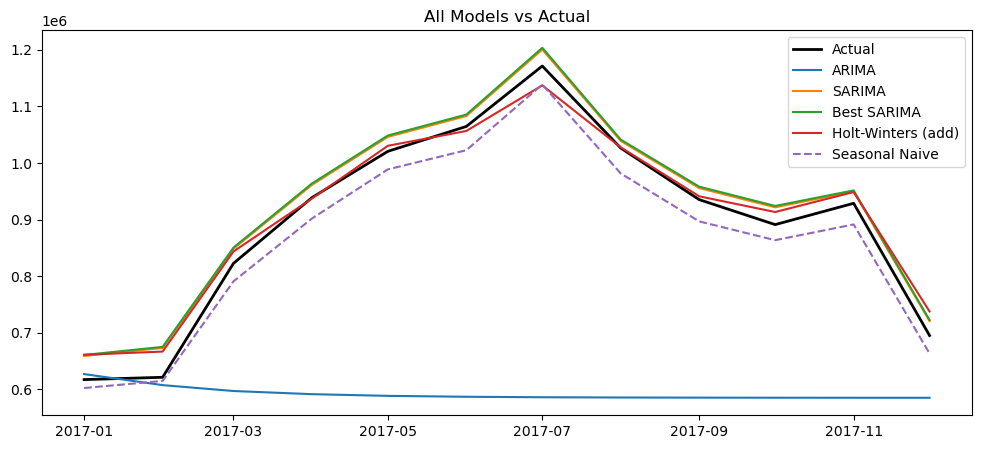

In [37]:
# RMSE is one number per model, so we plot all forecasts to see where each one misses
plt.figure(figsize=(12,5))
plt.plot(test, label='Actual', color='black', linewidth=2)
plt.plot(arima_forecast, label='ARIMA')
plt.plot(sarima_forecast, label='SARIMA')
plt.plot(best_forecast, label='Best SARIMA')
plt.plot(hw_add_forecast, label='Holt-Winters (add)')
plt.plot(naive_forecast, label='Seasonal Naive', linestyle='--')
plt.legend()
plt.title("All Models vs Actual")
plt.show()

### Residual Diagnostics
A low RMSE doesn't prove the model is sound, so we check the residuals for leftover pattern

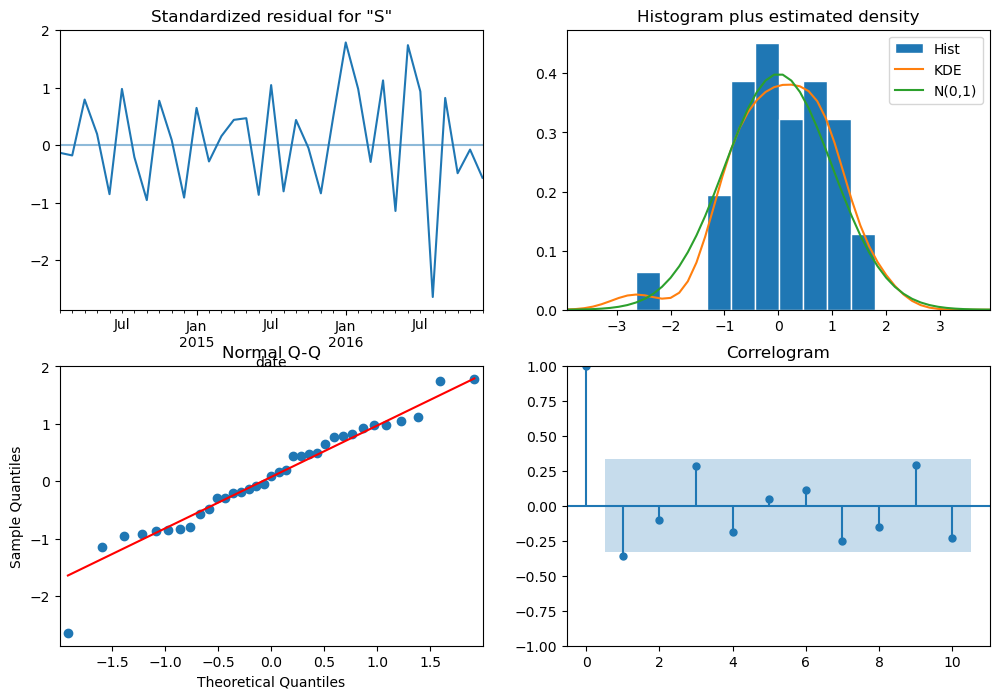

In [38]:
best_model.plot_diagnostics(figsize=(12,8))
plt.show()

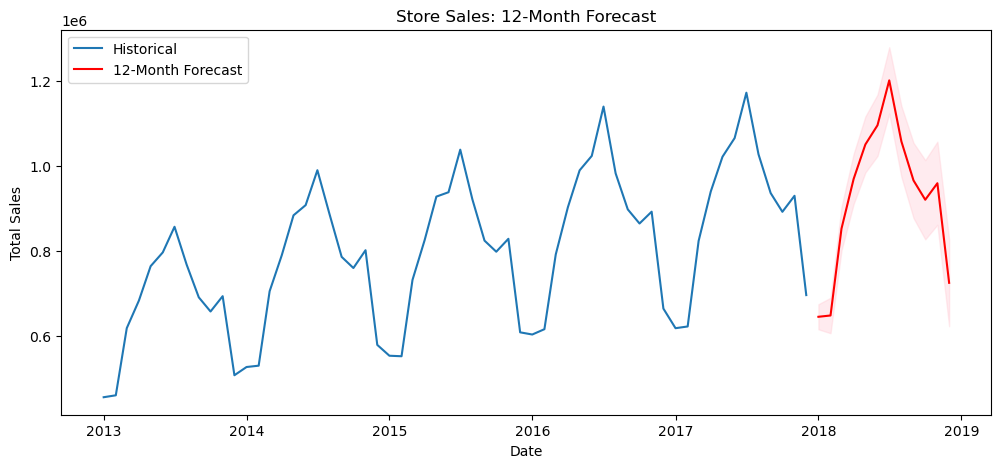

In [39]:
# The test set was only for judging, so we refit the best model on all 60 months
# and forecast 12 months ahead (a longer horizon would be unreliable with 60 points)

final_model = SARIMAX(df['Sales'],
                      order=best['order'],
                      seasonal_order=best['seasonal_order']).fit(disp=False)

future = final_model.get_forecast(steps=12)
future_mean = future.predicted_mean
future_ci = future.conf_int()

plt.figure(figsize=(12,5))
plt.plot(df['Sales'], label='Historical')
plt.plot(future_mean, label='12-Month Forecast', color='red')
plt.fill_between(future_ci.index,
                 future_ci.iloc[:, 0],
                 future_ci.iloc[:, 1],
                 color='pink', alpha=0.3)
plt.title("Store Sales: 12-Month Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.show()

## Findings and Conclusion

**Objective:** Forecast total monthly store sales by testing time series methods (decomposition, smoothing, ARIMA, SARIMA and Holt-Winters) and comparing them on held-out data.

**Data:** The dataset (train.csv) has 913,000 daily records of sales by store and item, with no missing values. Daily sales were summed across all stores and items into 60 monthly totals (January 2013 to December 2017). Monthly sales average about 795,000 (min 454,904, max 1,171,393). The series shows a clear upward trend and a strong yearly pattern: sales rise to a peak around July each year and fall to a low in the winter months.

**Stationarity and differencing**
- The ADF test on the raw series gave p = 7.0e-06 (stationary), which contradicts the plot. It used 11 lags on only 60 points, so it was treated as unreliable.
- KPSS gave p = 0.034 (non-stationary), which agrees with the visible trend and seasonality.
- A first difference alone was still non-stationary (ADF p = 0.519), and a seasonal difference alone was only borderline (p = 0.046).
- First plus seasonal (lag 12) differencing was stationary on both tests (ADF p = 7.3e-09, KPSS p = 0.1), so d = 1 and D = 1 with a seasonal period of 12.

**Setup:** The data was split by time, not randomly: 48 months for training (2013 to 2016) and the final 12 months (2017) for testing. Models were compared on RMSE, MAE and MAPE.

**Results on the 12 test months (ranked by RMSE)**

| Model | RMSE | MAE | MAPE |
|---|---|---|---|
| Holt-Winters (additive) | 26,608 | 21,302 | 2.77% |
| SARIMA(1,1,1)(1,1,1,12) | 28,890 | 27,044 | 3.34% |
| Best SARIMA by AIC: (0,1,0)(1,1,0,12) | 31,024 | 29,357 | 3.60% |
| Seasonal naive (same month last year) | 33,094 | 31,382 | 3.44% |
| Holt-Winters (multiplicative) | 43,027 | 41,611 | 4.69% |
| ARIMA(1,1,1) | 349,954 | 303,463 | 31.07% |

**Key findings**
1. **Seasonality is essential.** Plain ARIMA, with no seasonal terms, had a MAPE of 31.07%, roughly ten times worse than any seasonal model (2.77% to 4.69%).
2. **Holt-Winters (additive) was the best model** on all three metrics (RMSE 26,608, MAE 21,302, MAPE 2.77%). Its RMSE is about 20% lower than the seasonal naive benchmark (33,094), and its MAE about 32% lower. The multiplicative version was clearly worse (MAPE 4.69%), which suggests the seasonal swings are roughly constant in size and do not grow with the sales level.
3. **The seasonal naive benchmark is hard to beat.** Its MAPE is 3.44%, so the original SARIMA (3.34%) is only slightly better, and the AIC-selected SARIMA (3.60%) is actually worse in MAPE. Beating the baseline in RMSE by only about 6% is a modest gain.
4. **The lowest AIC did not give the best test score.** The AIC search over 16 small orders picked SARIMA(0,1,0)(1,1,0,12) (AIC 767.8), but it scored worse on the test set (RMSE 31,024) than the original (1,1,1)(1,1,1,12) guess (28,890). The differences between models of this size are small relative to the 12-month test window.
5. **The original SARIMA(1,1,1)(1,1,1,12) had weak parameters.** None of its four AR/MA coefficients was statistically significant (p between 0.52 and 1.00), and the summary warned of a near-singular covariance matrix. This supports using the simpler AIC-selected structure.
6. **Residual diagnostics of the AIC-selected SARIMA look mostly acceptable.** Residuals are roughly normal and centred on zero, with one large negative residual near the end of the training period. The lag-1 autocorrelation sits slightly outside the confidence band, so a small amount of pattern may remain.
7. **Final forecast:** The AIC-selected SARIMA was refitted on all 60 months and used to forecast 2018. It repeats the yearly pattern (a low in early 2018, a peak of about 1.2 million in mid-2018) with a prediction band that widens over the year.

**Limitations**
- **Very little data.** There are only 60 monthly points, 4 full years for training and a single 12-month test window, so rankings between models with close scores (for example the two SARIMAs and the seasonal naive) are not reliable.
- **Order search was small.** Only orders of 0 or 1 were tried, and AIC measures training fit, not forecasting accuracy.
- **Aggregated data.** All stores and items were summed, so store-level or item-level patterns are hidden.
- **The final forecast does not use the best test model.** It uses the AIC-selected SARIMA rather than Holt-Winters (additive), which scored better on the test set.

**Next steps:** use rolling-origin (time series) cross-validation instead of a single 12-month test, compare Holt-Winters (additive) against SARIMA on the same folds, consider forecasting at store or item level, and check whether the 2018 forecast should come from Holt-Winters instead.